In [1]:
#1. 그래프 설정
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display
import statsmodels.formula.api as smf          # 다중선형회귀
from sklearn.ensemble import RandomForestRegressor   # 랜덤포레스트
from sklearn.model_selection import train_test_split  # 학습·평가 데이터 나누기
from sklearn.inspection import permutation_importance, PartialDependenceDisplay  # 변수 중요도, 변수별 영향 그래프
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # 성능 지표

# 그래프에 한글이 깨지지 않게 설치된 한글 폰트 지정
fonts = {f.name for f in font_manager.fontManager.ttflist}
for name in ['AppleGothic', 'Malgun Gothic', 'NanumGothic']:
    if name in fonts:
        plt.rcParams['font.family'] = name
        break
plt.rcParams['axes.unicode_minus'] = False
# 그래프 크기와 표 출력 형식
plt.rcParams['figure.figsize'] = (13, 5)
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 12)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
print('실행 Python:', sys.executable)

실행 Python: /opt/anaconda3/bin/python3.13


In [2]:
########## 2. 폴더 안의 실거래가 파일만 읽기 ##########
# 프로젝트 폴더 또는 바로 아래 notebooks 폴더에서 실행
filename = '서울_아파트_매매_실거래가_2017-2026_통합.xlsx'
root = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / filename).exists()), None)
if root is None:
    raise FileNotFoundError('프로젝트 폴더에서 실행하세요: ' + filename)
source = root / filename
# 모든 열을 글자로 읽어 0으로 시작하는 번지 등이 바뀌지 않게 함
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Workbook contains no default style')
    raw = pd.read_excel(source, sheet_name='아파트(매매) 실거래가', dtype=str)
print('분석 파일:', source.name)
print(f'원본: {len(raw):,}행 / {len(raw.columns)}개 열')
display(raw.head(3))

분석 파일: 서울_아파트_매매_실거래가_2017-2026_통합.xlsx
원본: 547,735행 / 21개 열


,NO,시군구,번지,본번,부번,단지명,...,도로명,해제사유발생일,거래유형,중개사소재지,등기일자,주택유형
0,1,서울특별시 중구 신당동,850,0850,0000,신당푸르지오,...,다산로36길 110,-,-,-,-,아파트
1,2,서울특별시 성북구 돈암동,609-1,0609,0001,한신,...,성북로4길 52,-,-,-,-,아파트
2,3,서울특별시 용산구 효창동,3-3,0003,0003,효삼골드빌,...,효창원로93길 14,-,-,-,-,아파트


In [3]:
########## 3. 서울 아파트 매매만 남기고 연식·면적·층 정리 ##########
# 열 이름과 값 앞뒤 공백 제거
df = raw.copy()
df.columns = df.columns.str.strip()
for col in df.columns:
    df[col] = df[col].astype('string').str.strip()

# '117,000' 같은 글자를 숫자 117000으로 변환
def numeric(series):
    return pd.to_numeric(series.str.replace(',', '', regex=False), errors='coerce').astype(float)

# 분석에 쓸 변수 만들기: 연식 = 계약한 해 - 건축년도
df['가격_만원'] = numeric(df['거래금액(만원)'])
df['면적_m2'] = numeric(df['전용면적(㎡)'])
df['층'] = numeric(df['층'])
df['계약년'] = numeric(df['계약년월'].str[:4])
df['연식'] = df['계약년'] - numeric(df['건축년도'])
# '서울특별시 중구 신당동'에서 '중구'만 꺼냄
df['자치구'] = df['시군구'].str.extract(r'^서울특별시\s+(\S+구)(?:\s|$)', expand=False)
# 해제사유발생일이 있으면 취소된 거래
cancelled = ~df['해제사유발생일'].fillna('').isin(['', '-', '0'])
seoul_apt = df['자치구'].notna() & df['주택유형'].eq('아파트').fillna(False)
valid = df['가격_만원'].gt(0) & df['면적_m2'].gt(0) & df['계약년'].notna()
# 지하층과 계약년보다 늦은 건축년도(분양권 등)는 제외
feature_ok = df['층'].ge(1) & df['연식'].ge(0)
# 네 조건을 모두 만족하는 거래만 분석에 사용
keep = (seoul_apt & ~cancelled & valid & feature_ok).fillna(False)
# 어떤 이유로 몇 건이 빠졌는지 표로 확인
display(pd.Series({
    '원본 행': len(df),
    '서울 아파트 외': int((~seoul_apt).sum()),
    '서울 아파트 해제 거래': int((seoul_apt & cancelled).sum()),
    '나머지 중 가격·면적·날짜 오류': int((seoul_apt & ~cancelled & ~valid.fillna(False)).sum()),
    '지하층·연식 음수': int((seoul_apt & ~cancelled & valid & ~feature_ok).fillna(False).sum()),
    '분석 거래': int(keep.sum()),
}, name='건수').to_frame())
df = df.loc[keep].copy()
df['가격_억원'] = df['가격_만원'] / 10000
# 가격은 고가 거래가 길게 늘어져 있어 로그를 씌워 분포를 고르게 함
df['log가격'] = np.log(df['가격_억원'])
print(f"연식 {df['연식'].min():.0f}~{df['연식'].max():.0f}년 / 면적 {df['면적_m2'].min():.0f}~{df['면적_m2'].max():.0f}㎡ / 층 {df['층'].min():.0f}~{df['층'].max():.0f}층")
print(f"자치구 수: {df['자치구'].nunique()} / 분석 거래: {len(df):,}건")

,건수
원본 행,547735
서울 아파트 외,0
서울 아파트 해제 거래,17606
나머지 중 가격·면적·날짜 오류,0
지하층·연식 음수,146
분석 거래,529983


연식 0~65년 / 면적 10~395㎡ / 층 1~69층
자치구 수: 25 / 분석 거래: 529,983건


연식구간 {'5년 이하': 9.5, '6~10년': 9.45, '11~20년': 7.5, '21~30년': 7.0, '30년 초과': 7.97}
면적구간 {'60㎡ 이하': 5.69, '60~85㎡': 8.45, '85~135㎡': 11.5, '135㎡ 초과': 20.0}
층구간 {'1~3층': 6.99, '4~10층': 7.3, '11~20층': 8.15, '21층 이상': 12.3}


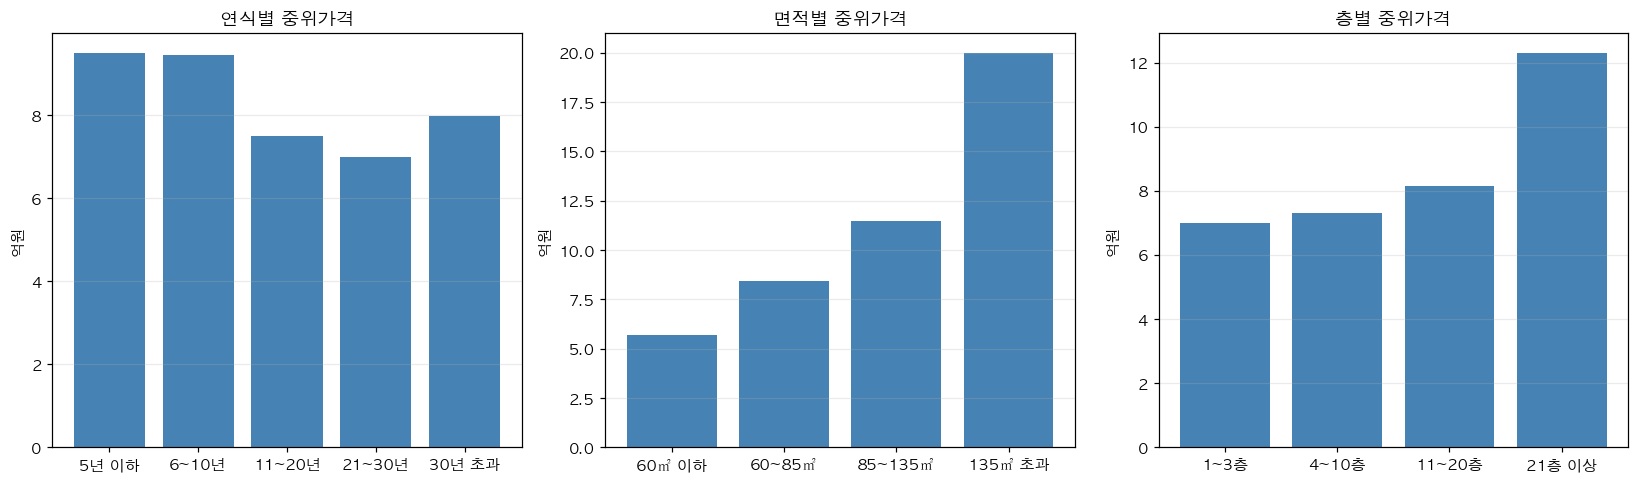

In [4]:
########## 4. 연식·면적·층 구간별 중위가격 ##########
# 구간별 단순 비교라 지역·시점 차이가 섞여 있음
# 연식·면적·층을 몇 개 구간으로 나눔
df['연식구간'] = pd.cut(df['연식'], bins=[-1, 5, 10, 20, 30, np.inf], labels=['5년 이하', '6~10년', '11~20년', '21~30년', '30년 초과'])
df['면적구간'] = pd.cut(df['면적_m2'], bins=[0, 60, 85, 135, np.inf], labels=['60㎡ 이하', '60~85㎡', '85~135㎡', '135㎡ 초과'])
df['층구간'] = pd.cut(df['층'], bins=[0, 3, 10, 20, np.inf], labels=['1~3층', '4~10층', '11~20층', '21층 이상'])
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, col in zip(axes, ['연식구간', '면적구간', '층구간']):
    # 구간별 거래 건수와 중위가격 계산 후 막대그래프
    table = df.groupby(col, observed=True)['가격_억원'].agg(['size', 'median'])
    ax.bar(table.index.astype(str), table['median'], color='steelblue')
    ax.set(title=f'{col[:-2]}별 중위가격', ylabel='억원')
    ax.grid(axis='y', alpha=0.25)
    print(col, dict(zip(table.index.astype(str), table['median'].round(2))))
plt.tight_layout()
plt.show()

In [5]:
########## 5. 상관계수 ##########
# 1에 가까울수록 같이 오르고, -1에 가까울수록 반대로 움직임, 0이면 관계 약함
display(df[['log가격', '연식', '면적_m2', '층']].corr().round(3))

,log가격,연식,면적_m2,층
log가격,1.0000,0.0240,0.6050,0.1830
연식,0.0240,1.0000,0.0380,-0.1830
면적_m2,0.6050,0.0380,1.0000,0.1000
층,0.1830,-0.1830,0.1000,1.0000


In [6]:
########## 6. 학습·평가 데이터 나누기 ##########
# 같은 기간 안에서 무작위 8:2 분할
# 학습 데이터로 모델을 만들고, 모델이 처음 보는 평가 데이터로 성능을 잼
train, test = train_test_split(df, test_size=0.2, random_state=42)
print(f'학습: {len(train):,}건 / 평가: {len(test):,}건')

학습: 423,986건 / 평가: 105,997건


In [7]:
########## 7. 다중선형회귀 ##########
# 자치구·계약년을 함께 넣어 지역·시점 차이를 통제, 가격은 로그 변환
# C(자치구), C(계약년): 구와 연도를 범주로 넣어 '같은 구, 같은 해'끼리 비교하는 효과
# HC1: 오차 크기가 고르지 않아도 p값이 덜 틀리게 보정
ols = smf.ols('log가격 ~ 연식 + 면적_m2 + 층 + C(자치구) + C(계약년)', data=train).fit(cov_type='HC1')
names = ['연식', '면적_m2', '층']
# 계수: 로그가격 변화량 / 1단위당_가격변화_%: 계수를 %로 바꾼 값
# 표준화계수: 단위가 다른 세 변수를 같은 기준으로 비교한 크기 / p값: 0.05보다 작으면 우연이 아니라고 봄
ols_result = pd.DataFrame({
    '계수': ols.params[names],
    '1단위당_가격변화_%': (np.exp(ols.params[names]) - 1) * 100,
    '표준화계수': ols.params[names] * train[names].std(),
    'p값': ols.pvalues[names],
})
print('1단위: 연식 1년 / 면적 1㎡ / 층 1층')
display(ols_result)
print(f'학습 데이터 R²: {ols.rsquared:.3f}')

1단위: 연식 1년 / 면적 1㎡ / 층 1층


,계수,1단위당_가격변화_%,표준화계수,p값
연식,-0.0010,-0.1032,-0.0110,0.0000
면적_m2,0.0115,1.1577,0.3470,0.0000
층,0.0101,1.0156,0.0638,0.0000


학습 데이터 R²: 0.701


In [8]:
########## 8. Random Forest ##########
# 랜덤포레스트에 넣을 변수. 자치구는 글자라 번호로 바꿔서 넣음
features = ['연식', '면적_m2', '층', '자치구코드', '계약년']
codes = {g: i for i, g in enumerate(sorted(df['자치구'].unique()))}
X_train = train.assign(자치구코드=train['자치구'].map(codes))[features].astype(float)
X_test = test.assign(자치구코드=test['자치구'].map(codes))[features].astype(float)
# 나무 200개를 만들어 예측을 평균, 잎 하나에 최소 5건이 남게 해 과적합 방지
rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
rf.fit(X_train, train['log가격'])
print('학습 완료: 나무', rf.n_estimators, '개')

학습 완료: 나무 200 개


In [9]:
########## 9. 두 모델 성능 비교 ##########
true = test['가격_억원']
# 로그가격으로 예측했으므로 exp로 다시 억원 단위로 되돌림
pred = {'다중선형회귀': np.exp(ols.predict(test)), 'Random Forest': np.exp(rf.predict(X_test))}
# MAE: 평균적으로 몇 억 틀리는지 / RMSE: 크게 틀린 거래에 더 벌점 / R²: 1에 가까울수록 잘 맞음
score = pd.DataFrame({
    name: {'MAE_억원': mean_absolute_error(true, p),
           'RMSE_억원': mean_squared_error(true, p) ** 0.5,
           'R²': r2_score(true, p)}
    for name, p in pred.items()
}).T
display(score.round(3))

,MAE_억원,RMSE_억원,R²
다중선형회귀,2.8050,5.4330,0.5080
Random Forest,1.0020,2.0720,0.9280


,중요도,표준편차
면적_m2,0.9993,0.0079
자치구코드,0.5781,0.0048
계약년,0.3044,0.0034
연식,0.2413,0.0036
층,0.0140,0.0004


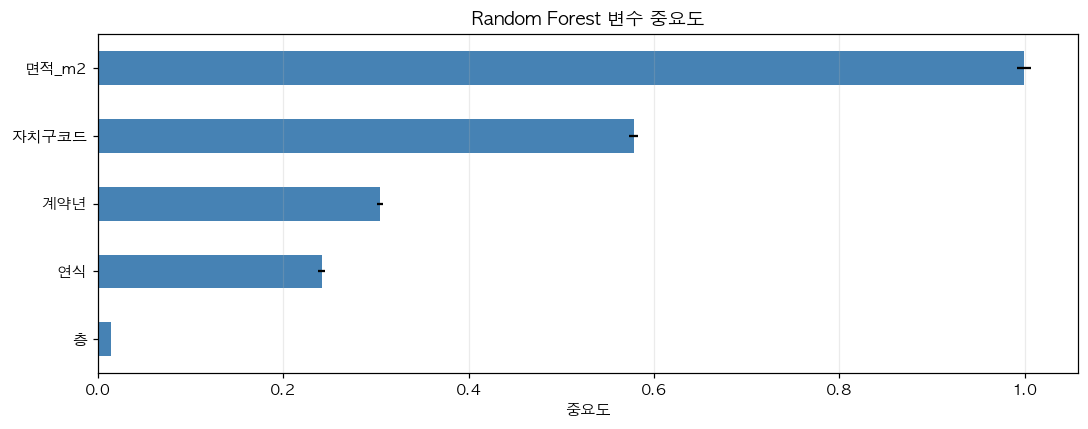

In [10]:
########## 10. 변수 중요도 (Permutation Importance) ##########
# 변수 값을 섞었을 때 예측이 나빠지는 정도. 인과적 영향력은 아님
# 계산이 오래 걸려 평가 데이터 중 2만 건만 사용
sample = X_test.sample(min(20000, len(X_test)), random_state=42)
# 변수 하나씩 값을 섞어 5번 반복하고, 예측이 얼마나 나빠지는지 평균
pi = permutation_importance(rf, sample, test.loc[sample.index, 'log가격'], n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({'중요도': pi.importances_mean, '표준편차': pi.importances_std}, index=features).sort_values('중요도', ascending=False)
display(importance)
# 막대가 길수록 가격 예측에 중요한 변수
ax = importance['중요도'].sort_values().plot.barh(figsize=(10, 4), color='steelblue', xerr=importance['표준편차'])
ax.set(title='Random Forest 변수 중요도', xlabel='중요도', ylabel='')
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

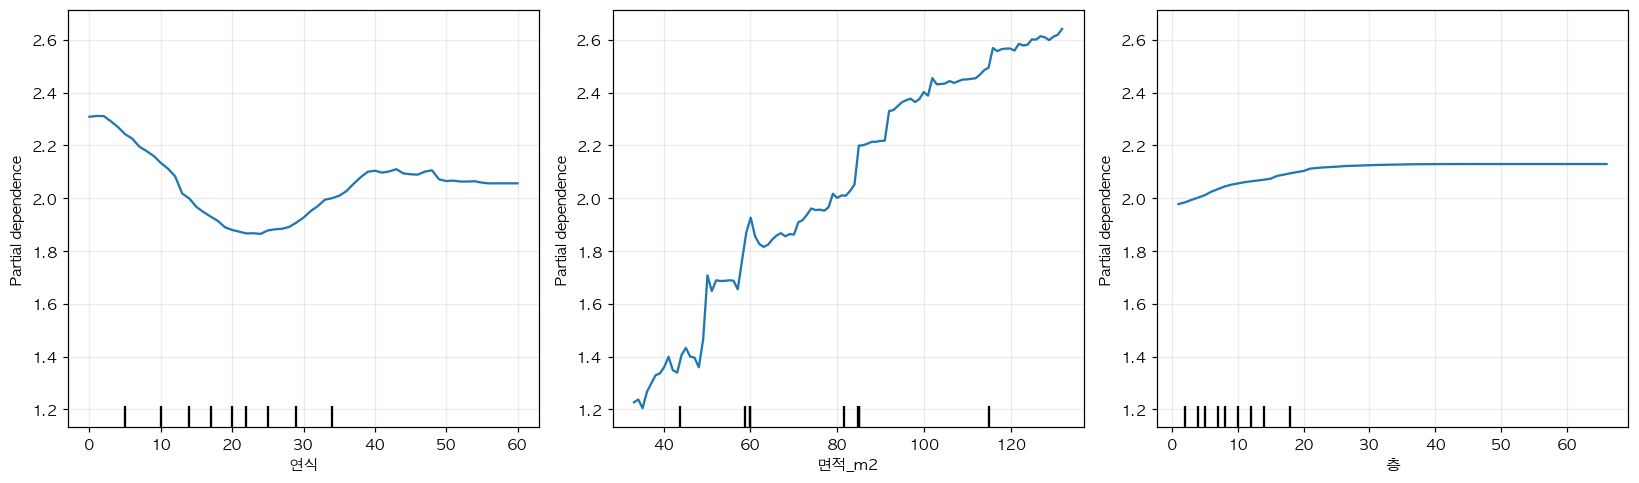

In [11]:
########## 11. 연식·면적·층에 따른 예측가격 변화 ##########
# 다른 변수는 그대로 두고 한 변수만 바꿨을 때의 평균 예측값(로그 가격)
# 선이 오르면 그 변수가 커질수록 예측가격이 오른다는 뜻
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
PartialDependenceDisplay.from_estimator(rf, sample, ['연식', '면적_m2', '층'], ax=axes)
for ax in fig.axes:
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [12]:
########## 12. 결과를 숫자로 확인 ##########
# 회귀 결과와 랜덤포레스트 중요도를 변수별로 나란히 출력
for name in names:
    print(f"{name}: 1단위당 {ols_result.loc[name, '1단위당_가격변화_%']:+.2f}% / 표준화계수 {ols_result.loc[name, '표준화계수']:+.3f} / RF 중요도 {importance.loc[name, '중요도']:.3f}")
print('RF 중요도 순위:', ' > '.join(importance.index))
# 두 모델 중 평가 R²가 더 높은 모델
best = score['R²'].idxmax()
print(f"평가 R²가 높은 모델: {best} ({score.loc[best, 'R²']:.3f}, MAE {score.loc[best, 'MAE_억원']:.2f}억원)")
print('회귀계수는 직선 관계를 가정한 값이고, RF 중요도는 비선형 관계까지 반영한 예측 기여도입니다.')
print('단지 입지·브랜드·재건축 여부 등 빠진 변수의 영향이 연식·면적·층에 섞여 있을 수 있습니다.')

연식: 1단위당 -0.10% / 표준화계수 -0.011 / RF 중요도 0.241
면적_m2: 1단위당 +1.16% / 표준화계수 +0.347 / RF 중요도 0.999
층: 1단위당 +1.02% / 표준화계수 +0.064 / RF 중요도 0.014
RF 중요도 순위: 면적_m2 > 자치구코드 > 계약년 > 연식 > 층
평가 R²가 높은 모델: Random Forest (0.928, MAE 1.00억원)
회귀계수는 직선 관계를 가정한 값이고, RF 중요도는 비선형 관계까지 반영한 예측 기여도입니다.
단지 입지·브랜드·재건축 여부 등 빠진 변수의 영향이 연식·면적·층에 섞여 있을 수 있습니다.
